[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/HybridQNN_AdversarialHistopathology_Baral2023.ipynb)

# Adversarial attacks on a hybrid quantum transfer-learning classifier for histopathological cancer detection: Baral et al. (2023) step by step

**Paper.** Biswaraj Baral, Reek Majumdar, Bhavika Bhalgamiya, Taposh Dutta Roy, *"Adversarial attacks on hybrid classical-quantum Deep Learning models for Histopathological Cancer Detection"*, arXiv:2309.06377 (2023), <https://arxiv.org/abs/2309.06377>.

**What this notebook does.**
1. Downloads real **PatchCamelyon (PCam)** histopathology patches (lymph-node sections, label = tumour tissue in the centre of the patch) from a public Hugging Face mirror, keeps a class-balanced random subset (the paper also used 1,000 / 5,000 / 10,000 of the 327,680 patches), and cuts the central 48 x 48 pixels (a stated choice that keeps the label-defining region and makes CPU attacks affordable).
2. Builds the paper's models: a frozen ImageNet **ResNet-18** feature extractor with (a) a classical head (`Linear -> ReLU -> Linear`), or (b) a **hybrid classical-quantum head** (`Linear -> 4-qubit variational quantum circuit -> Linear`, PennyLane `TorchLayer`) in two circuit variants, **VQC-1** and **VQC-6** (the two circuits of the paper's Table II for ResNet-18 with 10,000 images), plus a small CNN trained from scratch.
3. Runs the paper's three white-box, untargeted attacks (**FGSM, PGD, DeepFool**) on every model with epsilon in {0.05, 0.15, 0.25}, exactly the grid of the paper's Table II.
4. **Adds what the paper does not do:** attacks designed against the quantum model itself (a margin-loss PGD, a score-based black-box Square attack, transfer attacks between models, gradient-masking diagnostics) and a per-image *worst-case* accuracy. This matters because in several other papers of this repository "quantum models are more robust" turned out to be gradient masking, not robustness.
5. Rebuilds the paper's Table II for the ResNet-18 rows, prints the paper's numbers next to ours with a verdict per claim, then reads the paper critically.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. No account is needed (the dataset is public; a Hugging Face token is used only if one is present, see the data section). `FAST_MODE = True` is a short class demo; `FAST_MODE = False` uses the budgets written in the configuration cell. The numbers depend on the CPU load and on the random seed; the notebook states its seeds.

**What you get at the end.** Executed attack tables, the quantum circuits that were actually run, 2-D views of the real data, gradient-masking diagnostics, and an honest verdict on whether the hybrid model is more robust than the classical one.


## The paper in one page

**Problem.** Deep-learning classifiers for medical images can be fooled by small, targeted perturbations (adversarial examples). The paper asks whether a *hybrid classical-quantum* network, whose last hidden layer is a variational quantum circuit, resists such attacks better than a purely classical network, for the task *"does this histopathology patch contain cancer?"* (binary).

**Data.** PatchCamelyon (Veeling et al. 2018): 327,680 colour patches of 96 x 96 pixels from Camelyon16 lymph-node whole-slide images, balanced between tumour and non-tumour. The paper uses subsets of 1,000 (80:20 train/test), 5,000 and 10,000 images (60:20:20 train/validation/test).

**Models.** Classical: two custom CNNs, and ResNet-18 transfer learning (frozen feature layers, last fully connected layer replaced by `hidden(N) -> output(2)`). Hybrid: the same frozen feature extractor (ResNet-18, VGG-16, Inception-v3 or AlexNet), features reduced to `N` = number of qubits (2 to 8), then a variational quantum circuit (embedding layer of single-qubit gates, `d` variational layers with parameterised rotations and entangling gates, Pauli expectation values as output), then a two-neuron sigmoid output. Six circuits VQC-1 to VQC-6 with different *expressibility* (Sim et al. 2019) are tried. PennyLane `default.qubit`, PyTorch.

**Attacks.** White-box, untargeted: FGSM (Eq. 1, `x + eps * sign(grad)`), PGD (iterated FGSM with clipping) and DeepFool (iterative minimal-boundary-crossing perturbation), each with epsilon in {0.05, 0.15, 0.25} (Table II).

**Claims to check.** (i) Clean test accuracy of ResNet-18 models: classical 86.0 % (1,000 images) and 89.5 % (10,000), hybrid 88.5 % (1,000, VQC-1) and 82.35 % / 84.30 % (10,000, VQC-1 / VQC-6). (ii) Under attack the hybrid models keep a higher accuracy than the classical ResNet-18 (FGSM 46 to 78 % vs 17 to 20 %; DeepFool 16 to 49 % vs 16 to 18 %; PGD 45 to 56 % vs 10 to 38 %). (iii) The accuracy of the hybrid VQC-1 model *rises* with epsilon under FGSM (50.9 %, 69.7 %, 77.8 %). (iv) Models trained without transfer learning are more robust than the classical ResNet-18. (v) The expressibility of VQC-1 and VQC-6 is 1.431 and 0.011. (vi) Conclusion: "hybrid classical-quantum models are more resilient than classical ones".


### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | PCam, subsets of 1,000 / 5,000 / 10,000 images | PCam test split of the Hugging Face mirror `zacharielegault/PatchCamelyon` (32,768 real patches, 96 x 96, JPEG). Class-balanced random subset of `N_IMAGES` (FAST: 1,000, full: 10,000). `CHOICE:` the mirror is JPEG, the original PCam is HDF5. |
| Resolution | not stated (96 x 96, probably resized for the CNNs) | `CHOICE:` centre crop of `CROP = 48` pixels at native resolution (PCam's label refers to the centre 32 x 32 pixels), no resampling. Reason: gradient attacks through ResNet-18 on a shared CPU. |
| Split | 80:20 (1,000 images), 60:20:20 otherwise | 60:20:20 train/validation/test for every size (validation only for choosing the training epoch). |
| Feature extractor | ResNet-18 / VGG-16 / Inception-v3 / AlexNet, ImageNet weights, initial layers frozen | ResNet-18 only (the paper's best), torchvision ImageNet weights, completely frozen, eval-mode BatchNorm. |
| Classical head | `N` features -> hidden layer of `N` neurons (ReLU or sigmoid) -> 2 outputs | `Linear(512, 4) -> ReLU -> Linear(4, 2)`. `CHOICE:` `N = 4` to match the 4-qubit models, softmax cross-entropy instead of two sigmoids. |
| Hybrid head | `Linear -> VQC -> output`, 4 qubits for the ResNet-18 / 10,000-image rows | `Linear(512, 4) -> tanh * pi/2 -> VQC (4 qubits) -> Linear(4, 2)`, the structure of the PennyLane "quantum transfer learning" demo; PennyLane `default.qubit`, exact, no shot noise. |
| VQC-1 and VQC-6 | drawn only as figures (not in the text); expressibility 1.431 and 0.011 | `CHOICE:` circuits 1 and 6 of Sim et al. (2019), the reference the paper cites for expressibility: VQC-1 = `RX, RZ` on every qubit per layer (no entanglement); VQC-6 = `RX, RZ`, a full ladder of controlled-`RX` gates, `RX, RZ`. The number of layers is chosen in section 4 so that the computed expressibility is closest to the paper's value. |
| Embedding | single-qubit gates (H, U, RX, RY, RZ) | `Hadamard` then `RY(q_in)` on every qubit. |
| Read-out | expectation of X, Y or Z | `<Z>` on every qubit. |
| Training | not stated | Adam, cross-entropy, `EPOCHS` epochs, the epoch with the best validation accuracy is kept. |
| Classical CNN without transfer learning | "custom CNN", architecture not given | `CHOICE:` a 3-convolution CNN trained from scratch on the same images. |
| FGSM | `x + eps * sign(grad)` | Same, cross-entropy loss, clip to [0, 1]. Pixels are in [0, 1], so eps = 0.25 is a very large perturbation (an L-infinity ball of 64 grey levels). |
| PGD | iterated FGSM, clipped to the eps-ball, step size not stated | `CHOICE:` random start, `PGD_STEPS` steps of size `2.5 * eps / steps`, last iterate returned. |
| DeepFool | iterative boundary crossing; "epsilon" column | `CHOICE:` epsilon is the *overshoot* (as in IBM ART: `x + (1 + eps) * r`); this is consistent with the paper's DeepFool accuracies being almost flat in eps. Run against the true label; images that are already misclassified are left unchanged. |
| Metric | accuracy on the adversarial versions of the test images | Same: accuracy on all attacked images, i.e. including those misclassified before the attack. Attacks are run on a stratified subset of `N_ATTACK` test images (attacks through ResNet-18 are the expensive part), clean accuracy is reported on the whole test set. |
| Hardware | PennyLane `default.qubit` | Same; torch on one CPU thread. `IBM_TOKEN` is unused (no hardware runs, as in the paper). |


In [1]:
# Installs, pinned to the versions this notebook was tested with. Colab already ships numpy, pandas,
# scikit-learn, matplotlib, torch and torchvision. A session restart is NOT required.
import sys
IN_COLAB = "google.colab" in sys.modules
try:
    import pennylane
    _ok = pennylane.__version__ == "0.45.1"
except Exception:
    _ok = False
if IN_COLAB or not _ok:
    !pip -q install "pennylane==0.45.1" huggingface_hub pyarrow seaborn


In [2]:
# ---------------------------------------------------------------- configuration (every tunable constant)
FAST_MODE = False                 # True: short class demo; False: the budgets of the committed run (see the *_FULL values)
SEED = 42
DATA_DIR = "data"                # downloads and caches live here (never inside a git repo)
HF_REPO, HF_FILE = "zacharielegault/PatchCamelyon", "data/test-00000-of-00001.parquet"   # public PCam mirror, 136 MB
DELETE_DOWNLOAD_AFTER_CACHE = True   # the 136 MB parquet is deleted once the subset is cached
CROP = 48                        # CHOICE: centre crop (pixels) of the 96 x 96 patch
N_IMAGES = 1000 if FAST_MODE else 10000          # paper: 1,000 / 5,000 / 10,000
TEST_FRAC, VAL_FRAC = 0.2, 0.2   # 60:20:20
N_QUBITS = 4                     # paper's ResNet-18 / 10,000-image hybrids use 4 qubits
Q_LAYERS = {"vqc1": 1, "vqc6": 1}     # CHOICE: layers per circuit, set from the expressibility study in section 4
EPOCHS_HEAD = 10 if FAST_MODE else 15           # classical / hybrid head training epochs
EPOCHS_CNN = 5 if FAST_MODE else 6              # CNN trained from scratch
BATCH_HEAD, LR_HEAD = (64 if FAST_MODE else 128), 3e-3
EXPR_PAIRS = 1000 if FAST_MODE else 5000        # parameter pairs for the expressibility estimate (Sim et al.: 5000)
# attacks
EPSILONS = [0.05, 0.15, 0.25]    # the paper's grid
N_ATTACK = 40 if FAST_MODE else 100             # test images attacked (stratified); clean accuracy uses the whole test split
ATT_BS = 40                      # attack batch size
PGD_STEPS = 4 if FAST_MODE else 10
DEEPFOOL_MAX_ITER = 8 if FAST_MODE else 15
ADAPT_STEPS = 6 if FAST_MODE else 10            # margin-loss PGD (adaptive attack)
ADAPT_RESTARTS = 1
SQUARE_QUERIES = 20 if FAST_MODE else 40        # score-based black-box queries per image
IBM_TOKEN = ""                   # unused: no hardware runs


In [3]:
import os, io, sys, time, math, copy, shutil, random, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore", category=UserWarning)
torch.set_num_threads(1)             # shared / small machines: one thread keeps memory and CPU use small

# Hugging Face token: optional (the dataset is public). Resolved only here and never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_everything(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| N_IMAGES =", N_IMAGES, "| N_ATTACK =", N_ATTACK, "| Hugging Face token available:", HF_TOKEN is not None)


python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1
torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1
FAST_MODE = False | N_IMAGES = 10000 | N_ATTACK = 100 | Hugging Face token available: True


## 1. Data: real PatchCamelyon patches

PCam labels a 96 x 96 patch as positive (1) if the central 32 x 32 pixel region contains at least one pixel of tumour tissue. The Hugging Face mirror used here stores the 32,768 patches of the PCam *test* split (class-balanced, JPEG). The 136 MB parquet file is downloaded once, a class-balanced random subset of `N_IMAGES` patches is drawn with `SEED` (the file is sorted by class, so the draw is over the whole file), the central `CROP` x `CROP` pixels are cut out, the subset is cached as a small `.npz`, and the parquet file is deleted. Nothing is simulated or relabelled: every image is a real tissue patch and every label is the dataset's own.


In [4]:
CACHE = os.path.join(DATA_DIR, f"pcam_n{N_IMAGES}_c{CROP}_s{SEED}.npz")

def load_pcam():
    if os.path.exists(CACHE):
        d = np.load(CACHE); print("cache found:", CACHE, "| images", d["X"].shape)
        return d["X"], d["y"], d["idx"]
    import pyarrow.parquet as pq
    from PIL import Image
    from huggingface_hub import hf_hub_download
    t0 = time.time(); hf_dir = os.path.join(DATA_DIR, "hf")
    kw = dict(repo_type="dataset", local_dir=hf_dir)
    if HF_TOKEN: kw["token"] = HF_TOKEN
    path = hf_hub_download(HF_REPO, HF_FILE, **kw)
    print(f"downloaded {os.path.basename(path)}: {os.path.getsize(path)/1e6:.0f} MB in {time.time()-t0:.0f}s")
    pf = pq.ParquetFile(path)
    lab = pf.read(columns=["label"])["label"].to_numpy()
    r = np.random.default_rng(SEED)
    sel = np.sort(np.concatenate([r.choice(np.where(lab == c)[0], N_IMAGES // 2, replace=False) for c in (0, 1)]))
    sizes = [pf.metadata.row_group(i).num_rows for i in range(pf.metadata.num_row_groups)]
    off = np.cumsum([0] + sizes)
    lo = (96 - CROP) // 2
    X = np.zeros((len(sel), CROP, CROP, 3), np.uint8); y = np.zeros(len(sel), np.int64); k = 0
    for g in range(len(sizes)):
        m = sel[(sel >= off[g]) & (sel < off[g + 1])] - off[g]
        if len(m) == 0: continue
        t = pf.read_row_group(g).take(m.tolist())
        for im, l in zip(t["image"].to_pylist(), t["label"].to_numpy()):
            img = Image.open(io.BytesIO(im["bytes"])).convert("RGB"); assert img.size == (96, 96)
            X[k] = np.asarray(img.crop((lo, lo, lo + CROP, lo + CROP))); y[k] = l; k += 1
    assert k == len(sel)
    np.savez_compressed(CACHE, X=X, y=y, idx=sel)
    print(f"subset cached: {os.path.getsize(CACHE)/1e6:.0f} MB, total {time.time()-t0:.0f}s")
    if DELETE_DOWNLOAD_AFTER_CACHE:
        shutil.rmtree(hf_dir, ignore_errors=True); print("deleted the downloaded parquet file")
    return X, y, sel

X_img, y_all, src_idx = load_pcam()
perm = rng.permutation(len(y_all)); X_img, y_all, src_idx = X_img[perm], y_all[perm], src_idx[perm]   # the file is class-sorted: shuffle
print("images:", X_img.shape, X_img.dtype, "| labels:", dict(zip(*np.unique(y_all, return_counts=True))))


downloaded test-00000-of-00001.parquet: 136 MB in 5s


subset cached: 62 MB, total 38s
deleted the downloaded parquet file


images: (10000, 48, 48, 3) uint8 | labels: {np.int64(0): np.int64(5000), np.int64(1): np.int64(5000)}


## 2. Frozen ResNet-18 features and the train / validation / test split

The paper keeps the pre-trained layers fixed and only trains a new head. The ResNet-18 here is therefore completely frozen (`requires_grad = False`, BatchNorm in eval mode); its 512-dimensional global-pooling output is the input of every head. Because it is frozen, the features of the clean images can be computed once. The attacks later go through the *whole* network (pixels -> ResNet-18 -> head), as a white-box attacker would. Images are in [0, 1]; the ImageNet mean/std normalisation is part of the model, so epsilon is measured in pixel units.


In [5]:
def to_tensor(Xu8):
    return torch.from_numpy(Xu8).permute(0, 3, 1, 2).float() / 255.

class FrozenResNet18(nn.Module):
    def __init__(self):
        super().__init__()
        m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Identity(); self.net = m
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        for p in self.parameters(): p.requires_grad_(False)
        self.net.eval()
    def train(self, mode=True):              # BatchNorm statistics stay frozen whatever the caller does
        return super().train(False)
    def forward(self, x):
        return self.net((x - self.mean) / self.std)

backbone = FrozenResNet18().eval()
T_img = to_tensor(X_img); y_t = torch.tensor(y_all)
t0 = time.time(); feats = []
with torch.no_grad():
    for i in range(0, len(T_img), 200): feats.append(backbone(T_img[i:i + 200]))
Feat = torch.cat(feats); print(f"ResNet-18 features {tuple(Feat.shape)} in {time.time()-t0:.0f}s")

idx_all = np.arange(len(y_all))
tr_all, te_idx = train_test_split(idx_all, test_size=TEST_FRAC, stratify=y_all, random_state=SEED)
tr_idx, va_idx = train_test_split(tr_all, test_size=VAL_FRAC / (1 - TEST_FRAC), stratify=y_all[tr_all], random_state=SEED)
if N_ATTACK < len(te_idx):
    att_idx, _ = train_test_split(te_idx, train_size=N_ATTACK, stratify=y_all[te_idx], random_state=SEED)
else:
    att_idx = te_idx
print(f"train {len(tr_idx)} | validation {len(va_idx)} | test {len(te_idx)} | attacked test subset {len(att_idx)}")


ResNet-18 features (10000, 512) in 549s


train 6000 | validation 2000 | test 2000 | attacked test subset 100


## Dataset Exploration and Visualisation

This section looks at the real data the experiment uses. PCam has two ground-truth classes (the paper's task is binary: no tumour / tumour in the centre of the patch; the dataset has no finer labels). We print the shapes, the feature names and the label counts, plot the class distribution, show example patches, and project the real observations to 2-D three ways: (a) the raw PCA coordinates of the ResNet-18 features (PCA fitted on the training split), (b) the same two coordinates rescaled to [0, pi] (the range of a rotation angle; the hybrid model feeds the circuit with a learned `Linear(512, 4)` layer instead, whose angles are shown in section 3), and (c) a PCA of the raw pixels, which does not depend on ResNet at all.


Dataset: PatchCamelyon (Veeling et al. 2018), Hugging Face mirror zacharielegault/PatchCamelyon - test split of 32,768 patches; original size 96 x 96 px, 3 channels
subset used: (10000, 48, 48, 3) = (images, height, width, channels), uint8 in [0, 255]; centre crop 48 x 48
feature names: pixel intensities R,G,B at (row, col) of the crop; ResNet-18 features resnet_f0 ... resnet_f511
ResNet-18 feature matrix: (10000, 512)
original label values: {0: 'normal tissue (no tumour in the centre 32x32)', 1: 'tumour tissue in the centre 32x32'}


no tumour    5000
tumour       5000


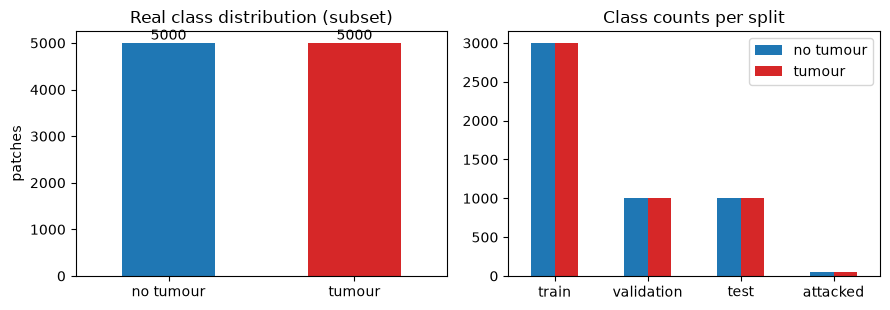

           train  validation  test  attacked
no tumour   3000        1000  1000        50
tumour      3000        1000  1000        50


In [6]:
CLASS_NAMES = {0: "no tumour", 1: "tumour"}
print("Dataset: PatchCamelyon (Veeling et al. 2018), Hugging Face mirror", HF_REPO, "- test split of 32,768 patches; original size 96 x 96 px, 3 channels")
print("subset used:", X_img.shape, "= (images, height, width, channels), uint8 in [0, 255]; centre crop", CROP, "x", CROP)
print("feature names: pixel intensities R,G,B at (row, col) of the crop; ResNet-18 features resnet_f0 ... resnet_f511")
print("ResNet-18 feature matrix:", tuple(Feat.shape))
print("original label values:", {0: "normal tissue (no tumour in the centre 32x32)", 1: "tumour tissue in the centre 32x32"})
cnt = pd.Series(y_all).map(CLASS_NAMES).value_counts().reindex(["no tumour", "tumour"])
print(cnt.to_string())
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
cnt.plot.bar(ax=ax[0], color=["tab:blue", "tab:red"], rot=0); ax[0].set_title("Real class distribution (subset)"); ax[0].set_ylabel("patches")
for i, v in enumerate(cnt.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
split_cnt = pd.DataFrame({"train": np.bincount(y_all[tr_idx], minlength=2), "validation": np.bincount(y_all[va_idx], minlength=2),
                          "test": np.bincount(y_all[te_idx], minlength=2), "attacked": np.bincount(y_all[att_idx], minlength=2)}, index=["no tumour", "tumour"])
split_cnt.T.plot.bar(ax=ax[1], rot=0, color=["tab:blue", "tab:red"]); ax[1].set_title("Class counts per split"); plt.tight_layout(); plt.show()
print(split_cnt.to_string())


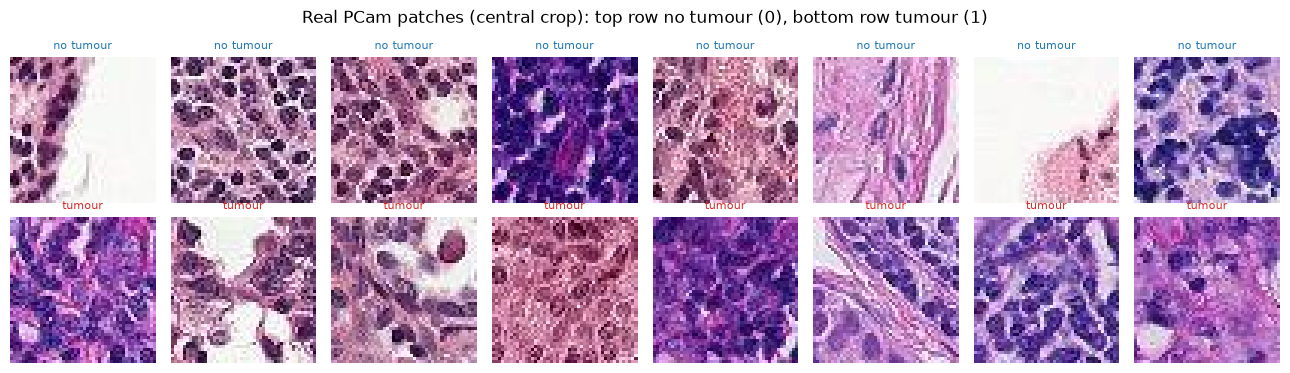

In [7]:
# Example patches (real images, ground-truth label above each)
fig, axs = plt.subplots(2, 8, figsize=(13, 3.8))
for lab in (0, 1):
    pick = np.where(y_all == lab)[0][:8]
    for j, k in enumerate(pick):
        axs[lab, j].imshow(X_img[k]); axs[lab, j].set_title(CLASS_NAMES[lab], color=["tab:blue", "tab:red"][lab], fontsize=8); axs[lab, j].axis("off")
plt.suptitle("Real PCam patches (central crop): top row no tumour (0), bottom row tumour (1)"); plt.tight_layout(); plt.show()


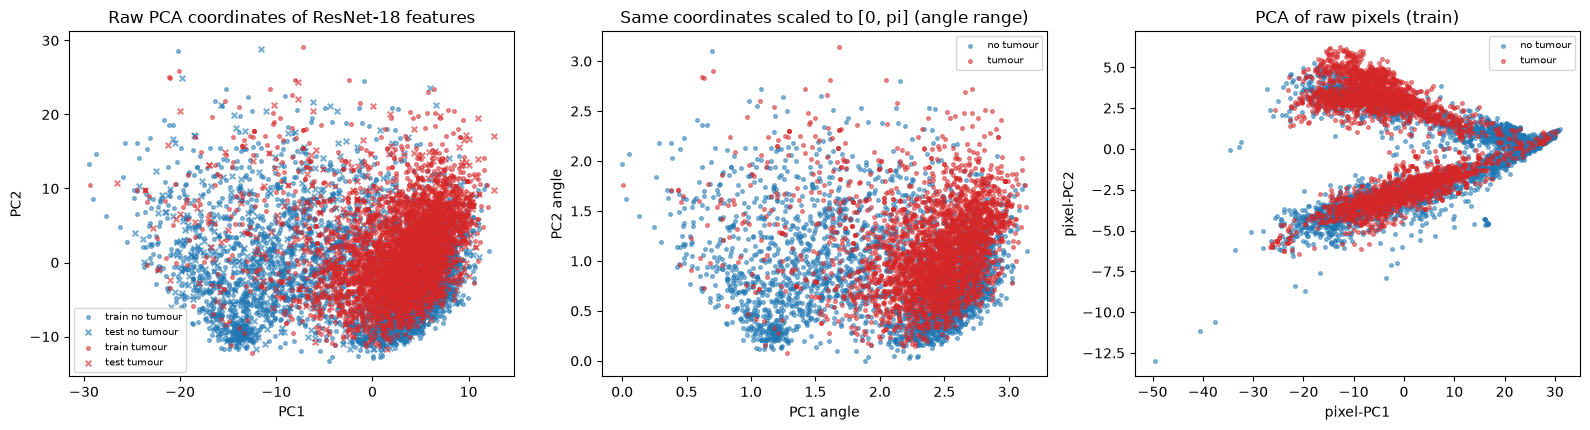

logistic regression on the first 2 PCA components: test accuracy 0.652


logistic regression on the first 4 PCA components: test accuracy 0.669


logistic regression on all 512 features: test accuracy 0.786


In [8]:
# (a) raw PCA coordinates (fitted on the training split), (b) the same coordinates scaled to [0, pi] with training min/max (test clipped), (c) PCA of raw pixels
colors = np.array(["tab:blue", "tab:red"])
F_np = Feat.numpy()
pca_f = PCA(n_components=2, random_state=SEED).fit(F_np[tr_idx]); Z = pca_f.transform(F_np)
z_lo, z_hi = Z[tr_idx].min(0), Z[tr_idx].max(0)
ang = np.clip((Z - z_lo) / (z_hi - z_lo), 0, 1) * np.pi
pix = X_img.reshape(len(X_img), -1).astype(np.float32) / 255.
pca_p = PCA(n_components=2, random_state=SEED).fit(pix[tr_idx]); P = pca_p.transform(pix)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for lab in (0, 1):
    m = y_all[tr_idx] == lab; ax[0].scatter(Z[tr_idx][m, 0], Z[tr_idx][m, 1], s=7, alpha=.5, c=colors[lab], label=f"train {CLASS_NAMES[lab]}")
    m = y_all[te_idx] == lab; ax[0].scatter(Z[te_idx][m, 0], Z[te_idx][m, 1], s=16, marker="x", alpha=.6, c=colors[lab], label=f"test {CLASS_NAMES[lab]}")
    m = y_all[tr_idx] == lab; ax[1].scatter(ang[tr_idx][m, 0], ang[tr_idx][m, 1], s=7, alpha=.5, c=colors[lab], label=CLASS_NAMES[lab])
    ax[2].scatter(P[tr_idx][m, 0], P[tr_idx][m, 1], s=7, alpha=.5, c=colors[lab], label=CLASS_NAMES[lab])
ax[0].set_title("Raw PCA coordinates of ResNet-18 features"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(fontsize=7)
ax[1].set_title("Same coordinates scaled to [0, pi] (angle range)"); ax[1].set_xlabel("PC1 angle"); ax[1].set_ylabel("PC2 angle"); ax[1].legend(fontsize=7)
ax[2].set_title("PCA of raw pixels (train)"); ax[2].set_xlabel("pixel-PC1"); ax[2].set_ylabel("pixel-PC2"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
from sklearn.linear_model import LogisticRegression
for k in (2, 4, 512):
    pf_ = PCA(n_components=min(k, 512), random_state=SEED).fit(F_np[tr_idx]) if k < 512 else None
    A = pf_.transform(F_np) if pf_ is not None else F_np
    lr = LogisticRegression(max_iter=3000).fit(A[tr_idx], y_all[tr_idx])
    print(f"logistic regression on {'all 512 features' if k == 512 else f'the first {k} PCA components'}: test accuracy {lr.score(A[te_idx], y_all[te_idx]):.3f}")


## Quantum Circuit Architecture

The paper shows its six circuits (VQC-1 to VQC-6) only as figures and states their expressibility and qubit count. For the ResNet-18 rows with 10,000 images, Table II uses **VQC-1** (expressibility 1.431, 4 qubits) and **VQC-6** (0.011, 4 qubits). Expressibility in the sense of Sim et al. (2019) is the KL divergence between the fidelity distribution of the circuit's random states and the Haar distribution (0 = as expressive as possible). Circuits 1 and 6 of Sim et al. are the least and one of the most expressive circuits of that paper, which matches the paper's two values, so we use them. **Assumptions where the paper is silent:** (i) *embedding*: `Hadamard` followed by `RY(q_in)` on each of the 4 qubits, with `q_in = tanh(Linear(features)) * pi/2` (quantum transfer learning demo of PennyLane); (ii) VQC-1 layer: `RX(theta)` then `RZ(theta)` on every qubit, no entangling gate; (iii) VQC-6 layer: `RX, RZ` on every qubit, then controlled-`RX` gates for every ordered pair of qubits (12 gates, target and control both descending), then `RX, RZ` again; (iv) number of layers `Q_LAYERS`, chosen from the expressibility study below; (v) read-out `<Z>` on all 4 qubits into a classical `Linear(4, 2)`; (vi) exact state-vector simulation (`default.qubit`), no shot noise, no hardware noise.


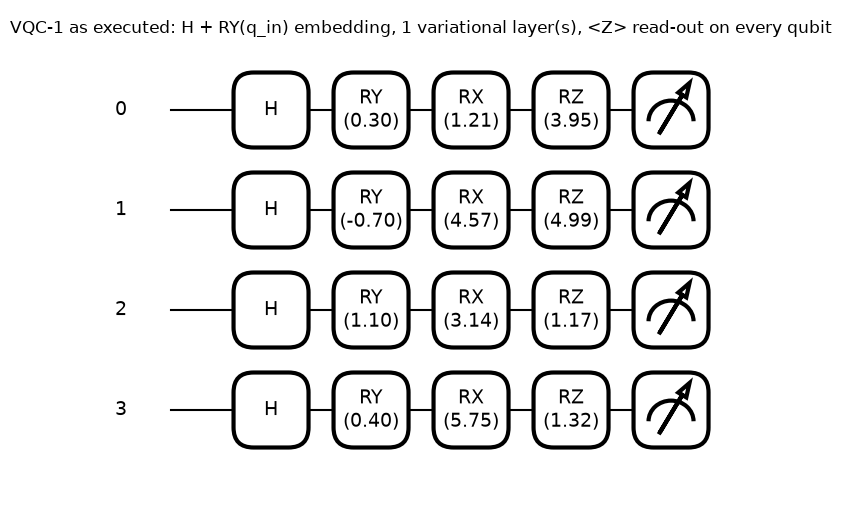

VQC-1: qubits 4 | gates 16 {'Hadamard': 4, 'RY': 4, 'RX': 4, 'RZ': 4} | depth 4 | trainable quantum parameters 8 (1 layer(s) x 8) | classical parameters around it: Linear(512,4)=2052, Linear(4,2)=10


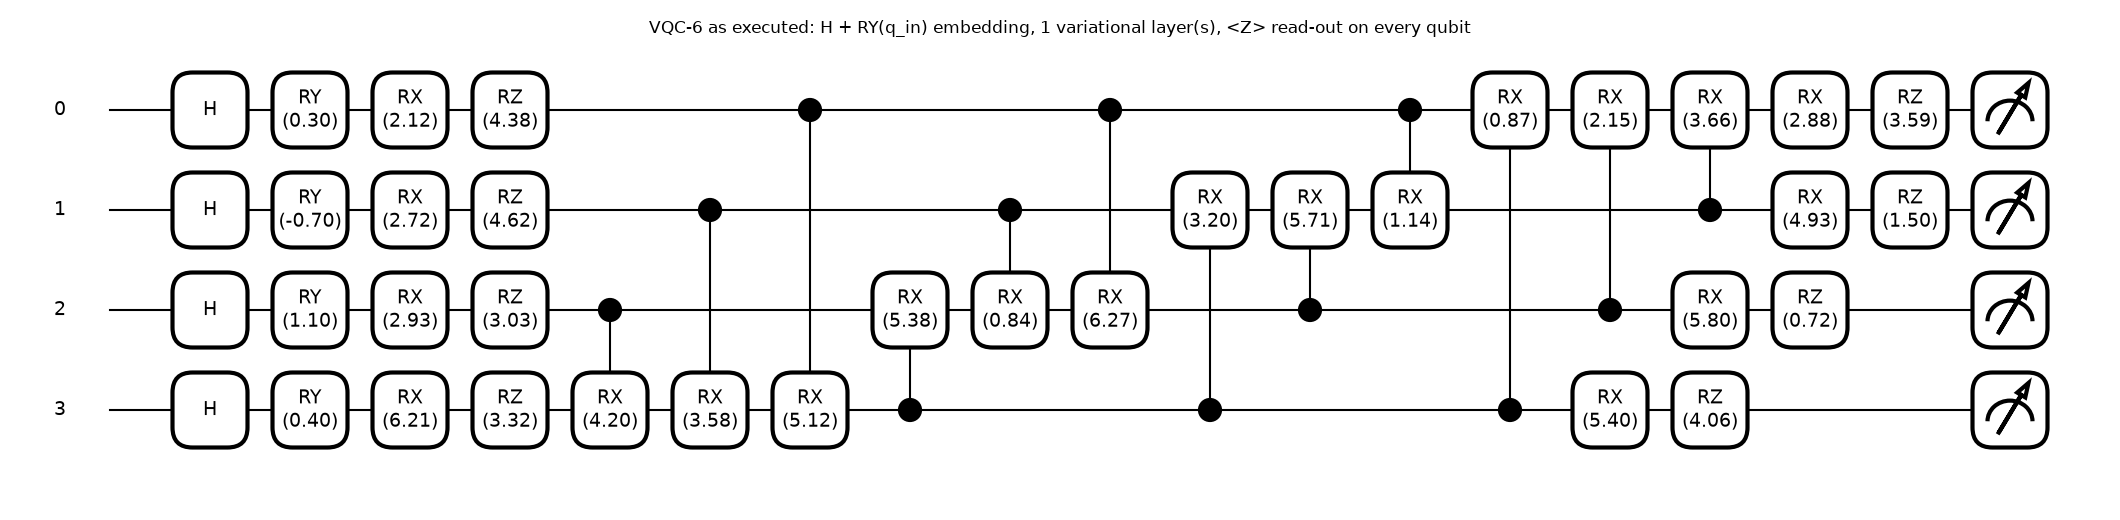

VQC-6: qubits 4 | gates 36 {'Hadamard': 4, 'RY': 4, 'RX': 8, 'RZ': 8, 'CRX': 12} | depth 17 | trainable quantum parameters 28 (1 layer(s) x 28) | classical parameters around it: Linear(512,4)=2052, Linear(4,2)=10


In [9]:
dev = qml.device("default.qubit", wires=N_QUBITS)
PPL = {"vqc1": 2 * N_QUBITS, "vqc6": 4 * N_QUBITS + N_QUBITS * (N_QUBITS - 1)}   # trainable parameters per layer

def embed_ops(x):
    for q in range(N_QUBITS): qml.Hadamard(wires=q)
    for q in range(N_QUBITS): qml.RY(x[..., q], wires=q)

def ansatz_ops(w, kind, L):
    # CHOICE: circuits 1 and 6 of Sim et al. (2019); w[..., layer, parameter]
    n = N_QUBITS
    for l in range(L):
        for q in range(n): qml.RX(w[..., l, q], wires=q)
        for q in range(n): qml.RZ(w[..., l, n + q], wires=q)
        if kind == "vqc6":
            k = 2 * n
            for t in reversed(range(n)):
                for c in reversed(range(n)):
                    if c != t:
                        qml.CRX(w[..., l, k], wires=[c, t]); k += 1
            for q in range(n): qml.RX(w[..., l, k + q], wires=q)
            for q in range(n): qml.RZ(w[..., l, k + n + q], wires=q)

def full_ops(x, w, kind, L):
    embed_ops(x); ansatz_ops(w, kind, L)

def make_qnode(kind, L):
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        full_ops(inputs, weights, kind, L)
        return [qml.expval(qml.PauliZ(q)) for q in range(N_QUBITS)]
    return circuit

x_demo = torch.tensor([0.3, -0.7, 1.1, 0.4], dtype=torch.float64)
for kind, title in (("vqc1", "VQC-1"), ("vqc6", "VQC-6")):
    L = Q_LAYERS[kind]; qn = make_qnode(kind, L)
    w_demo = torch.rand(L, PPL[kind], dtype=torch.float64) * 2 * math.pi
    fig, ax = qml.draw_mpl(qn, decimals=2)(x_demo, w_demo)
    fig.suptitle(f"{title} as executed: H + RY(q_in) embedding, {L} variational layer(s), <Z> read-out on every qubit"); plt.show()
    res = qml.specs(qn)(x_demo, w_demo)["resources"]
    nq = getattr(res, "num_allocs", None) or getattr(res, "num_wires", N_QUBITS)
    print(f"{title}: qubits {nq} | gates {res.num_gates} {dict(res.gate_types)} | depth {res.depth} | "
          f"trainable quantum parameters {L * PPL[kind]} ({L} layer(s) x {PPL[kind]}) | classical parameters around it: Linear(512,4)={512*4+4}, Linear(4,2)={4*2+2}")


In [10]:
# The "exact simulator" is PennyLane's default.qubit. Independent check: simulate the same gate list with a hand-written NumPy
# state-vector simulator (using only each gate's 2x2 / 4x4 matrix) and compare with the QNode output for random inputs and weights.
def np_simulate(ops, n):
    psi = np.zeros((2,) * n, dtype=complex); psi[(0,) * n] = 1.0
    for op in ops:
        k = len(op.wires); U = np.asarray(qml.matrix(op)).reshape((2,) * (2 * k))
        psi = np.tensordot(U, psi, axes=(list(range(k, 2 * k)), list(op.wires)))
        psi = np.moveaxis(psi, list(range(k)), list(op.wires))
    return psi

def np_expval_z(psi, n):
    p = np.abs(psi) ** 2
    return np.array([np.sum(p * np.moveaxis(np.where(np.arange(2) == 0, 1.0, -1.0).reshape((2,) + (1,) * (n - 1)), 0, q)) for q in range(n)])

r = np.random.default_rng(SEED)
for kind in ("vqc1", "vqc6"):
    L = Q_LAYERS[kind]; qn = make_qnode(kind, L); worst = 0.0
    for _ in range(5):
        x = r.uniform(-1.5, 1.5, N_QUBITS); w = r.uniform(0, 2 * np.pi, (L, PPL[kind]))
        ops = qml.tape.make_qscript(full_ops)(x, w, kind, L).operations
        ref = np_expval_z(np_simulate(ops, N_QUBITS), N_QUBITS)
        got = np.array([float(v) for v in qn(torch.tensor(x), torch.tensor(w))])
        worst = max(worst, np.abs(ref - got).max())
        assert np.allclose(ref, got, atol=1e-9), (kind, ref, got)
    print(f"{kind}: QNode == independent NumPy state-vector simulation of its own gate list ({len(ops)} gates), max |difference| = {worst:.1e}")


vqc1: QNode == independent NumPy state-vector simulation of its own gate list (16 gates), max |difference| = 4.4e-16


vqc6: QNode == independent NumPy state-vector simulation of its own gate list (36 gates), max |difference| = 4.7e-16


circuit  layers  expressibility  paper    gap
  VQC-1       1           0.303  1.431 -1.128
  VQC-1       2           0.196  1.431 -1.235
  VQC-1       3           0.207  1.431 -1.224
  VQC-1       4           0.204  1.431 -1.227
  VQC-6       1           0.003  0.011 -0.008
  VQC-6       2           0.004  0.011 -0.007
  VQC-6       3           0.004  0.011 -0.007
  VQC-6       4           0.003  0.011 -0.008
layers whose expressibility is closest to the paper: {'vqc1': 1, 'vqc6': 2} | layers used in this notebook (Q_LAYERS): {'vqc1': 1, 'vqc6': 1}


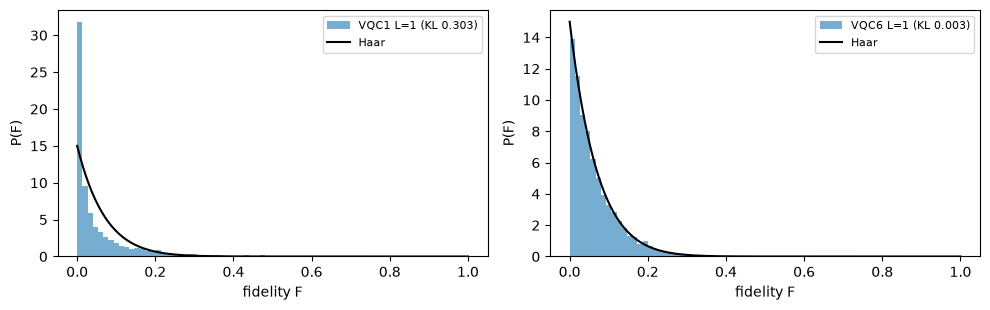

In [11]:
# Expressibility (Sim et al. 2019): KL( P_circuit(F) || P_Haar(F) ), F = |<psi(a)|psi(b)>|^2 for random parameter pairs, 75 bins.
def expressibility(kind, L, pairs=EXPR_PAIRS, seed=SEED, bins=75):
    r = np.random.default_rng(seed)
    @qml.qnode(dev)
    def state(w):
        ansatz_ops(w, kind, L); return qml.state()
    wa = r.uniform(0, 2 * np.pi, (pairs, L, PPL[kind])); wb = r.uniform(0, 2 * np.pi, (pairs, L, PPL[kind]))
    a, b = np.asarray(state(wa)), np.asarray(state(wb))
    Fid = np.abs(np.sum(a.conj() * b, axis=1)) ** 2
    h, edges = np.histogram(Fid, bins=bins, range=(0, 1)); Pc = h / h.sum()
    N = 2 ** N_QUBITS; Ph = (1 - edges[:-1]) ** (N - 1) - (1 - edges[1:]) ** (N - 1)
    m = Pc > 0
    return float(np.sum(Pc[m] * np.log(Pc[m] / Ph[m]))), Fid

EXPR_PAPER = {"vqc1": 1.431, "vqc6": 0.011}
rows = []
for kind in ("vqc1", "vqc6"):
    for L in (1, 2, 3, 4):
        e, _ = expressibility(kind, L); rows.append(dict(circuit=kind.upper().replace("VQC", "VQC-"), layers=L, expressibility=round(e, 3), paper=EXPR_PAPER[kind], gap=round(e - EXPR_PAPER[kind], 3)))
expr_df = pd.DataFrame(rows); print(expr_df.to_string(index=False))
best = {k: int(expr_df[expr_df.circuit == k.upper().replace("VQC", "VQC-")].assign(a=lambda d: d.gap.abs()).sort_values("a").iloc[0].layers) for k in ("vqc1", "vqc6")}
print("layers whose expressibility is closest to the paper:", best, "| layers used in this notebook (Q_LAYERS):", Q_LAYERS)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a_, kind in zip(ax, ("vqc1", "vqc6")):
    e, Fid = expressibility(kind, Q_LAYERS[kind]); N = 2 ** N_QUBITS
    a_.hist(Fid, bins=75, range=(0, 1), density=True, alpha=.6, label=f"{kind.upper()} L={Q_LAYERS[kind]} (KL {e:.3f})")
    f_ = np.linspace(0, 1, 400); a_.plot(f_, (N - 1) * (1 - f_) ** (N - 2), "k", label="Haar"); a_.set_xlabel("fidelity F"); a_.set_ylabel("P(F)"); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 3. The four models

* **CNN** (classical, no transfer learning): three convolution blocks trained from scratch on the images (`CHOICE:` architecture, the paper gives none).
* **ResNet18** (classical): frozen ResNet-18 -> `Linear(512, 4) -> ReLU -> Linear(4, 2)` (the paper's Fig. 3 with `N = 4`).
* **Hybrid VQC-1 / Hybrid VQC-6**: frozen ResNet-18 -> `Linear(512, 4)` -> `tanh * pi/2` -> 4-qubit circuit (VQC-1 or VQC-6, section 4) -> `<Z>` on each qubit -> `Linear(4, 2)` (the paper's Fig. 4). The circuit is a PennyLane `TorchLayer`, so gradients flow through the exact simulator by back-propagation.

All heads are trained on the cached ResNet-18 features of the training split (Adam, cross-entropy), keeping the epoch with the best validation accuracy. The test split is never used for any choice.


In [12]:
class ClassicalHead(nn.Module):
    def __init__(self):
        super().__init__(); self.pre = nn.Linear(512, N_QUBITS); self.post = nn.Linear(N_QUBITS, 2)
    def forward(self, f): return self.post(F.relu(self.pre(f)))

class HybridHead(nn.Module):
    def __init__(self, kind):
        super().__init__(); self.kind = kind; L = Q_LAYERS[kind]
        self.pre = nn.Linear(512, N_QUBITS)
        self.q = qml.qnn.TorchLayer(make_qnode(kind, L), {"weights": (L, PPL[kind])}, init_method=lambda t: nn.init.normal_(t, 0.0, 0.5))   # CHOICE: init
        self.post = nn.Linear(N_QUBITS, 2)
    def angles(self, f): return torch.tanh(self.pre(f)) * (math.pi / 2)         # q_in of the embedding layer
    def forward(self, f):
        a = self.angles(f); out = self.q(a)
        assert out.shape == (len(f), N_QUBITS), out.shape
        return self.post(out.to(f.dtype))

class Net(nn.Module):                      # pixels in [0,1] -> logits (what an attacker queries)
    def __init__(self, backbone, head):
        super().__init__(); self.backbone, self.head = backbone, head
    def forward(self, x): return self.head(self.backbone(x))

class SmallCNN(nn.Module):                 # CHOICE: classical CNN without transfer learning
    def __init__(self):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.f = nn.Sequential(blk(3, 32), blk(32, 64), blk(64, 128), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.out = nn.Linear(128, 2)
    def forward(self, x): return self.out(self.f((x - 0.5) / 0.25))

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
tr_t, va_t, te_t, att_t = (torch.tensor(a) for a in (tr_idx, va_idx, te_idx, att_idx))
acc_of = lambda z, y: (z.argmax(1) == y).float().mean().item()

def train_head(head, name, epochs, seed=SEED):
    seed_everything(seed); opt = torch.optim.Adam(head.parameters(), lr=LR_HEAD)
    Ftr, ytr, Fva, yva = Feat[tr_t], y_t[tr_t], Feat[va_t], y_t[va_t]
    g = torch.Generator().manual_seed(seed); hist = []; best = (-1.0, None, 0); t0 = time.time()
    for ep in range(epochs):
        head.train(); perm = torch.randperm(len(Ftr), generator=g); tot = 0.0
        for i in range(0, len(perm), BATCH_HEAD):
            b = perm[i:i + BATCH_HEAD]; opt.zero_grad(); loss = F.cross_entropy(head(Ftr[b]), ytr[b]); loss.backward(); opt.step(); tot += loss.item() * len(b)
        head.eval()
        with torch.no_grad(): va = acc_of(head(Fva), yva)
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(Ftr), val_acc=va))
        if va > best[0]: best = (va, copy.deepcopy(head.state_dict()), ep + 1)
    head.load_state_dict(best[1]); head.eval()
    print(f"{name}: {epochs} epochs in {time.time()-t0:.0f}s | best validation accuracy {best[0]:.3f} at epoch {best[2]} | trainable parameters {n_params(head)}")
    return pd.DataFrame(hist)

HIST = {}
seed_everything(SEED); ch = ClassicalHead(); HIST["ResNet18"] = train_head(ch, "ResNet18 (classical head)", EPOCHS_HEAD)
for kind, nm in (("vqc1", "Hybrid VQC-1"), ("vqc6", "Hybrid VQC-6")):
    seed_everything(SEED); hh = HybridHead(kind); HIST[nm] = train_head(hh, nm, EPOCHS_HEAD)
    globals()["head_" + kind] = hh


ResNet18 (classical head): 15 epochs in 6s | best validation accuracy 0.821 at epoch 12 | trainable parameters 2062


Hybrid VQC-1: 15 epochs in 79s | best validation accuracy 0.819 at epoch 9 | trainable parameters 2070


Hybrid VQC-6: 15 epochs in 258s | best validation accuracy 0.807 at epoch 9 | trainable parameters 2090


In [13]:
def train_cnn(epochs, seed=SEED):
    seed_everything(seed); cnn = SmallCNN(); opt = torch.optim.Adam(cnn.parameters(), lr=2e-3)
    Xtr, ytr, Xva, yva = T_img[tr_t], y_t[tr_t], T_img[va_t], y_t[va_t]
    g = torch.Generator().manual_seed(seed); hist = []; best = (-1.0, None, 0); t0 = time.time()
    for ep in range(epochs):
        cnn.train(); perm = torch.randperm(len(Xtr), generator=g); tot = 0.0
        for i in range(0, len(perm), 64):
            b = perm[i:i + 64]; xb = Xtr[b]
            if torch.rand(1, generator=g).item() < 0.5: xb = xb.flip(3)           # light augmentation: flips
            if torch.rand(1, generator=g).item() < 0.5: xb = xb.flip(2)
            opt.zero_grad(); loss = F.cross_entropy(cnn(xb), ytr[b]); loss.backward(); opt.step(); tot += loss.item() * len(b)
        cnn.eval()
        with torch.no_grad(): va = acc_of(torch.cat([cnn(Xva[i:i + 200]) for i in range(0, len(Xva), 200)]), yva)
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(Xtr), val_acc=va))
        if va > best[0]: best = (va, copy.deepcopy(cnn.state_dict()), ep + 1)
    cnn.load_state_dict(best[1]); cnn.eval()
    print(f"CNN (from scratch): {epochs} epochs in {time.time()-t0:.0f}s | best validation accuracy {best[0]:.3f} at epoch {best[2]} | trainable parameters {n_params(cnn)}")
    return cnn, pd.DataFrame(hist)

cnn, HIST["CNN"] = train_cnn(EPOCHS_CNN)
MODELS = {"CNN": cnn.eval(),
          "ResNet18": Net(backbone, ch).eval(),
          "Hybrid VQC-1": Net(backbone, head_vqc1).eval(),
          "Hybrid VQC-6": Net(backbone, head_vqc6).eval()}


CNN (from scratch): 6 epochs in 1282s | best validation accuracy 0.838 at epoch 6 | trainable parameters 93954


pixel-input models reproduce head(cached ResNet-18 features): OK


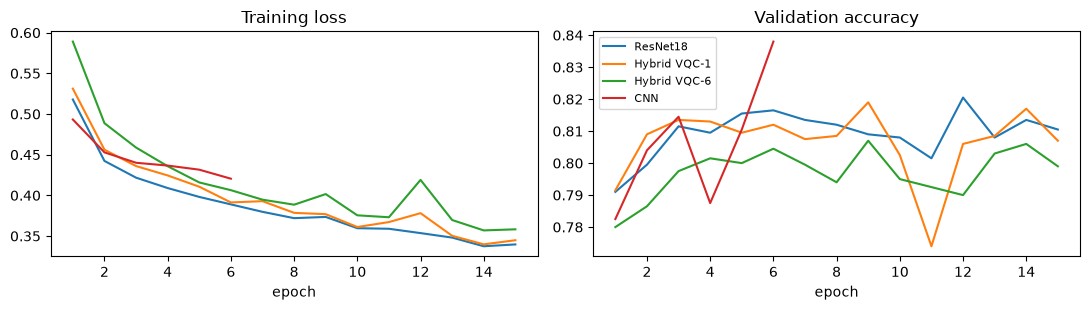

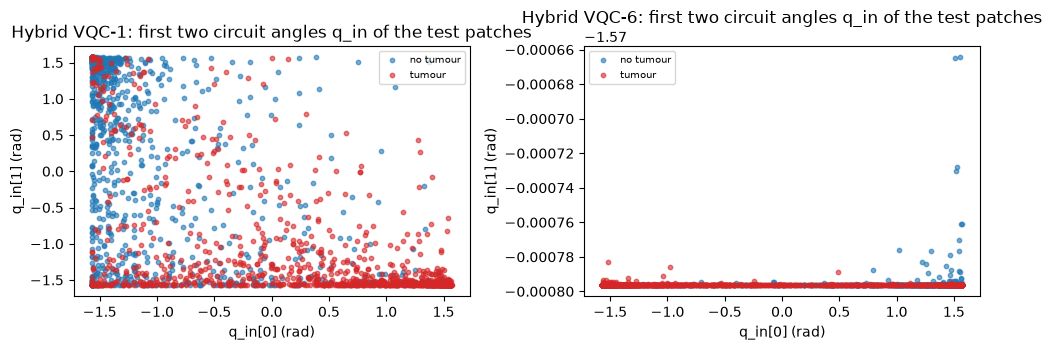

clean test accuracy (whole test split, n = 2000): {'CNN': 0.8065, 'ResNet18': 0.792, 'Hybrid VQC-1': 0.7985, 'Hybrid VQC-6': 0.791}


In [14]:
# Clean accuracy on the whole test split; check that the image -> logits model equals head(cached features)
def predict(model, X, bs=200):
    with torch.no_grad(): return torch.cat([model(X[i:i + bs]) for i in range(0, len(X), bs)])
CLEAN = {}
for nm, m in MODELS.items():
    zt = predict(m, T_img[te_t]); CLEAN[nm] = acc_of(zt, y_t[te_t])
    if nm != "CNN":
        with torch.no_grad(): ref = m.head(Feat[te_t[:50]])
        assert torch.allclose(zt[:50], ref, atol=1e-4), nm
print("pixel-input models reproduce head(cached ResNet-18 features): OK")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for nm, h in HIST.items():
    ax[0].plot(h.epoch, h.train_loss, label=nm); ax[1].plot(h.epoch, h.val_acc, label=nm)
ax[0].set_title("Training loss"); ax[1].set_title("Validation accuracy"); ax[0].set_xlabel("epoch"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
# angles the hybrid models feed to the circuit for the first two test images, per class (real observations, coloured by label)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a_, (nm, hd) in zip(ax, (("Hybrid VQC-1", head_vqc1), ("Hybrid VQC-6", head_vqc6))):
    with torch.no_grad(): A = hd.angles(Feat[te_t]).numpy()
    for lab in (0, 1):
        m = y_all[te_idx] == lab; a_.scatter(A[m, 0], A[m, 1], s=10, alpha=.6, c=colors[lab], label=CLASS_NAMES[lab])
    a_.set_title(f"{nm}: first two circuit angles q_in of the test patches"); a_.set_xlabel("q_in[0] (rad)"); a_.set_ylabel("q_in[1] (rad)"); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("clean test accuracy (whole test split, n = %d):" % len(te_idx), {k: round(v, 4) for k, v in CLEAN.items()})


## 4. The attacks

All attacks are white-box, untargeted and bounded in the L-infinity norm (except DeepFool, which looks for the smallest L2 step across the decision boundary and is only clipped to the valid pixel range). Pixels are in [0, 1].

* **FGSM** (the paper's Eq. 1): `x_adv = clip(x + eps * sign(grad_x CE))`.
* **PGD**: `PGD_STEPS` signed-gradient steps of size `2.5 * eps / steps`, random start, projection onto the eps-ball and onto [0, 1]; the last iterate is returned (as in standard toolboxes).
* **DeepFool** (binary): linearise the logit difference `f = z1 - z0` and jump to the linearised boundary until the prediction flips, then scale the accumulated perturbation by `(1 + overshoot)`. `CHOICE:` the paper's "epsilon" for DeepFool is the overshoot.

**What the paper does not do (adaptive attacks).** A defence or a new model type must be attacked with attacks *designed against it*; low accuracy under the standard attacks above only gives an upper bound on robustness, and high accuracy under them can be gradient masking (loss surface that is flat or oscillating, so the signed gradient points the wrong way). We therefore add: (1) **PGD with a margin (Carlini-Wagner type) loss**, `z_wrong - z_true`, with restarts, which does not saturate when the softmax is confident; (2) a **Square Attack** (score-based, gradient-free, L-infinity), which ignores gradients altogether; (3) **transfer attacks**: PGD examples crafted on another model, evaluated here; (4) **diagnostics**: gradient norms at clean inputs, accuracy that rises with eps, and whether the gradient-free attack beats the gradient-based ones; (5) the **per-image worst case** over all L-infinity attacks.


In [15]:
def input_grad(model, x, y, loss="ce"):
    xr = x.clone().detach().requires_grad_(True); z = model(xr)
    if loss == "ce": L = F.cross_entropy(z, y, reduction="sum")
    else: L = (z.gather(1, (1 - y)[:, None]) - z.gather(1, y[:, None])).sum()      # margin: wrong logit minus true logit
    g, = torch.autograd.grad(L, xr)
    return g, z.detach()

def fgsm_from_grad(x, g, eps): return (x + eps * g.sign()).clamp(0, 1)

def pgd(model, x, y, eps, steps, loss="ce", restarts=1, track_best=False, gen=None):
    # CHOICE: step size 2.5*eps/steps, random start. track_best keeps, per image, the first iterate that fools the model.
    alpha = 2.5 * eps / steps; best = x.clone(); fooled = torch.zeros(len(x), dtype=torch.bool)
    for r in range(restarts):
        xa = (x + (torch.rand(x.shape, generator=gen) * 2 - 1) * eps).clamp(0, 1)
        for s in range(steps):
            g, z = input_grad(model, xa, y, loss)
            if track_best:
                wrong = z.argmax(1) != y; new = wrong & ~fooled; best[new] = xa[new]; fooled |= wrong
            xa = xa + alpha * g.sign(); xa = torch.min(torch.max(xa, x - eps), x + eps).clamp(0, 1)
        with torch.no_grad(): wrong = model(xa).argmax(1) != y
        if track_best:
            new = wrong & ~fooled; best[new] = xa[new]; fooled |= wrong
        else:
            best = xa
    if track_best: best[~fooled] = xa[~fooled]
    return best.detach()

def deepfool(model, x, y, overshoots, max_iter):
    # binary DeepFool on f = z1 - z0 against the TRUE label; images that are already misclassified are not touched
    r_tot = torch.zeros_like(x); stuck = torch.zeros(len(x), dtype=torch.bool)
    with torch.no_grad(): active = model(x).argmax(1) == y
    sgn = torch.where(y == 1, 1.0, -1.0)
    for it in range(max_iter):
        xc = (x + r_tot).clamp(0, 1).requires_grad_(True); z = model(xc); f = z[:, 1] - z[:, 0]
        g, = torch.autograd.grad(f.sum(), xc)
        active = active & ((f.detach() * sgn) > 0)
        if not active.any(): break
        gn2 = (g.flatten(1) ** 2).sum(1); stuck |= active & (gn2 < 1e-20)
        step = (-f.detach() / (gn2 + 1e-12)).view(-1, 1, 1, 1) * g
        r_tot = r_tot + step * active.view(-1, 1, 1, 1).float()
    return {ov: (x + (1 + ov) * r_tot).clamp(0, 1).detach() for ov in overshoots}, stuck

def square_attack(model, x, y, eps, n_queries, seed=SEED, p_init=0.1):
    # score-based black-box L-infinity attack (Andriushchenko et al. 2020), simplified: random-position squares of +-eps
    gen = torch.Generator().manual_seed(seed); n, c, h, w = x.shape
    def margin(xx, yy):
        with torch.no_grad():
            z = model(xx); return (z.gather(1, yy[:, None]) - z.gather(1, (1 - yy)[:, None])).squeeze(1)      # > 0: still correct
    xb = (x + eps * (torch.randint(0, 2, (n, c, 1, w), generator=gen).float() * 2 - 1)).clamp(0, 1); mb = margin(xb, y)
    for i in range(n_queries):
        act = (mb > 0).nonzero().flatten()
        if len(act) == 0: break
        p = p_init * 0.5 ** sum(i / n_queries >= t for t in (0.1, 0.25, 0.5, 0.75))
        s = min(max(int(round(math.sqrt(p * h * w))), 1), h); xc = xb[act].clone()
        for j, a in enumerate(act.tolist()):
            r0 = int(torch.randint(0, h - s + 1, (1,), generator=gen)); c0 = int(torch.randint(0, w - s + 1, (1,), generator=gen))
            sg = torch.randint(0, 2, (c, 1, 1), generator=gen).float() * 2 - 1
            xc[j, :, r0:r0 + s, c0:c0 + s] = (x[a, :, r0:r0 + s, c0:c0 + s] + eps * sg).clamp(0, 1)
        mc = margin(xc, y[act]); imp = mc < mb[act]; upd = act[imp]; xb[upd] = xc[imp]; mb[upd] = mc[imp]
    return xb

def correct(model, x, y):
    with torch.no_grad(): return (model(x).argmax(1) == y).numpy()

# sanity checks of the attack code on the classical ResNet-18: an attack must not leave the eps-ball and must lower the accuracy
m_ = MODELS["ResNet18"]; xs, ys = T_img[att_t[:20]], y_t[att_t[:20]]
xa = pgd(m_, xs, ys, 0.05, 3); assert (xa - xs).abs().max() <= 0.05 + 1e-6 and xa.min() >= 0 and xa.max() <= 1
g_, _ = input_grad(m_, xs, ys); xf = fgsm_from_grad(xs, g_, 0.05); assert (xf - xs).abs().max() <= 0.05 + 1e-6
print("attack code OK: perturbations stay inside the eps-ball and the [0,1] range; accuracy on 20 images: clean %.2f, FGSM %.2f, PGD %.2f" % (
    correct(m_, xs, ys).mean(), correct(m_, xf, ys).mean(), correct(m_, xa, ys).mean()))


attack code OK: perturbations stay inside the eps-ball and the [0,1] range; accuracy on 20 images: clean 0.90, FGSM 0.30, PGD 0.05


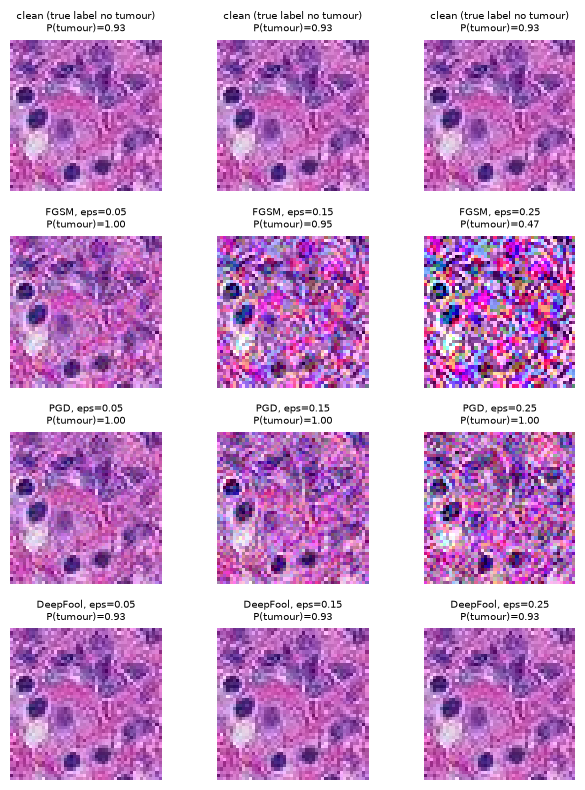

In [16]:
# Fig. 8 of the paper for one real test patch and the classical ResNet-18: rows = attacks, columns = eps
i0 = int(att_t[0]); x0, y0 = T_img[i0:i0 + 1], y_t[i0:i0 + 1]; m_ = MODELS["ResNet18"]
g0, _ = input_grad(m_, x0, y0); gen = torch.Generator().manual_seed(SEED)
df0, _ = deepfool(m_, x0, y0, EPSILONS, DEEPFOOL_MAX_ITER)
rows_ = {"clean": [x0] * 3, "FGSM": [fgsm_from_grad(x0, g0, e) for e in EPSILONS],
         "PGD": [pgd(m_, x0, y0, e, PGD_STEPS, gen=gen) for e in EPSILONS], "DeepFool": [df0[e] for e in EPSILONS]}
fig, axs = plt.subplots(4, 3, figsize=(6.5, 8))
for r_, (nm, imgs) in enumerate(rows_.items()):
    for c_, (e, im) in enumerate(zip(EPSILONS, imgs)):
        with torch.no_grad(): pr = m_(im).softmax(1)[0, 1].item()
        axs[r_, c_].imshow(im[0].permute(1, 2, 0).numpy()); axs[r_, c_].axis("off")
        axs[r_, c_].set_title(f"{nm}, eps={e}\nP(tumour)={pr:.2f}" if nm != "clean" else f"clean (true label {CLASS_NAMES[int(y0)]})\nP(tumour)={pr:.2f}", fontsize=7)
plt.tight_layout(); plt.show()


## 5. The paper's attacks on all four models (Table II)

For every model, the attacked test subset is attacked with FGSM, PGD and DeepFool at the three epsilon values. We also add a **random-sign noise** control (`x + eps * random sign`): if random noise of the same size already destroys the accuracy, the damage is not adversarial. The accuracy is counted over all attacked images (as in the paper's Table II), with the 95 % Wilson interval shown in the tables below.


In [17]:
R = {nm: {} for nm in MODELS}           # R[model][attack][eps] -> boolean array "still correct", one entry per attacked image
ADV_PGD = {nm: {} for nm in MODELS}     # PGD examples (kept for the transfer attacks)
DF_STATS = {}; GRAD_STATS = {}
XA, YA = T_img[att_t], y_t[att_t]
batches = [slice(i, min(i + ATT_BS, len(XA))) for i in range(0, len(XA), ATT_BS)]
t_start = time.time()
for nm, m in MODELS.items():
    t0 = time.time(); gen = torch.Generator().manual_seed(SEED)
    store = {k: {e: [] for e in EPSILONS} for k in ("noise", "FGSM", "PGD", "DeepFool")}; store["clean"] = {0.0: []}
    pg = {e: [] for e in EPSILONS}; gnorm, gzero, conf, dfn2, dfinf, dfstuck = [], [], [], [], [], []
    for sl in batches:
        x, y = XA[sl], YA[sl]
        store["clean"][0.0].append(correct(m, x, y))
        g, z = input_grad(m, x, y); gl1 = g.flatten(1).abs().sum(1); gnorm.append(gl1); conf.append(z.softmax(1).max(1).values)
        for e in EPSILONS:
            store["noise"][e].append(correct(m, (x + e * (torch.randint(0, 2, x.shape, generator=gen).float() * 2 - 1)).clamp(0, 1), y))
            store["FGSM"][e].append(correct(m, fgsm_from_grad(x, g, e), y))
            xp = pgd(m, x, y, e, PGD_STEPS, gen=gen); pg[e].append(xp); store["PGD"][e].append(correct(m, xp, y))
        dfx, stuck = deepfool(m, x, y, EPSILONS, DEEPFOOL_MAX_ITER); dfstuck.append(stuck)
        for e in EPSILONS: store["DeepFool"][e].append(correct(m, dfx[e], y))
        d = (dfx[EPSILONS[0]] - x).flatten(1); dfn2.append(d.norm(dim=1)); dfinf.append(d.abs().max(1).values)
    for k, v in store.items(): R[nm][k] = {e: np.concatenate(a) for e, a in v.items()}
    ADV_PGD[nm] = {e: torch.cat(a) for e, a in pg.items()}
    GRAD_STATS[nm] = dict(grad_l1=torch.cat(gnorm).numpy(), conf=torch.cat(conf).numpy())
    DF_STATS[nm] = dict(l2=torch.cat(dfn2).numpy(), linf=torch.cat(dfinf).numpy(), stuck=float(torch.cat(dfstuck).float().mean()))
    print(f"{nm}: standard attacks on {len(XA)} images in {time.time()-t0:.0f}s | clean acc on this subset {R[nm]['clean'][0.0].mean():.3f}", flush=True)
print(f"total {time.time()-t_start:.0f}s")


CNN: standard attacks on 100 images in 38s | clean acc on this subset 0.850


ResNet18: standard attacks on 100 images in 174s | clean acc on this subset 0.820


Hybrid VQC-1: standard attacks on 100 images in 163s | clean acc on this subset 0.770


Hybrid VQC-6: standard attacks on 100 images in 133s | clean acc on this subset 0.750


total 508s


In [18]:
# The paper's Table II, ResNet-18 and CNN rows (accuracy %, entries are [eps = 0.05, 0.15, 0.25])
PAPER_TABLE = {
    10000: {"CNN": dict(clean=80.95, FGSM=[30.40, 34.20, 50.20], DeepFool=[42.75, 43.40, 44.00], PGD=[39.35, 22.00, 22.55]),
            "ResNet18": dict(clean=89.50, FGSM=[19.70, 16.55, 17.90], DeepFool=[16.25, 17.29, 18.15], PGD=[38.35, 10.54, 10.50]),
            "Hybrid VQC-1": dict(clean=82.35, FGSM=[50.94, 69.69, 77.75], DeepFool=[46.00, 47.80, 48.80], PGD=[52.70, 49.95, 50.05]),
            "Hybrid VQC-6": dict(clean=84.30, FGSM=[54.05, 63.55, 62.35], DeepFool=[16.50, 20.34, 24.45], PGD=[55.65, 45.55, 45.35])},
    1000: {"ResNet18": dict(clean=86.00, FGSM=[31.00, 27.00, 34.50], DeepFool=[17.00, 16.50, 16.50], PGD=[30.00, 14.00, 14.00]),
           "Hybrid VQC-1": dict(clean=88.50, FGSM=[46.50, 60.50, 65.50], DeepFool=[38.00, 39.00, 39.50], PGD=[50.50, 50.00, 50.00])},
}
PAPER_N = 10000 if N_IMAGES >= 5000 else 1000
print("paper rows available for", PAPER_N, "images:", list(PAPER_TABLE[PAPER_N]))


paper rows available for 10000 images: ['CNN', 'ResNet18', 'Hybrid VQC-1', 'Hybrid VQC-6']


In [19]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, 100 * (c - h)), min(100.0, 100 * (c + h))
def acc_pct(nm, atk, e): return 100 * R[nm][atk][e].mean()
print(f"n = {len(XA)} attacked images: a 95 % interval on a single accuracy is about +-{(wilson(len(XA)//2, len(XA))[1]-wilson(len(XA)//2, len(XA))[0])/2:.1f} points near 50 %.")
rows = []
for nm in MODELS:
    row = {"model": nm, "clean (test split)": 100 * CLEAN[nm], "clean (attacked subset)": acc_pct(nm, "clean", 0.0)}
    for atk in ("FGSM", "DeepFool", "PGD", "noise"):
        for e in EPSILONS: row[f"{atk} {e}"] = acc_pct(nm, atk, e)
    rows.append(row)
T2 = pd.DataFrame(rows).set_index("model").round(1); print("Table II rebuilt (accuracy %, attacked subset):"); print(T2.to_string())
print("\nDeepFool perturbation size at overshoot %.2f (median over images): L2 / Linf" % EPSILONS[0])
for nm in MODELS: print(f"  {nm:13s} L2 {np.median(DF_STATS[nm]['l2']):.3f} | Linf {np.median(DF_STATS[nm]['linf']):.3f} | share of images where the gradient vanished: {DF_STATS[nm]['stuck']:.2f}")


n = 100 attacked images: a 95 % interval on a single accuracy is about +-9.6 points near 50 %.
Table II rebuilt (accuracy %, attacked subset):
              clean (test split)  clean (attacked subset)  FGSM 0.05  FGSM 0.15  FGSM 0.25  DeepFool 0.05  DeepFool 0.15  DeepFool 0.25  PGD 0.05  PGD 0.15  PGD 0.25  noise 0.05  noise 0.15  noise 0.25
model                                                                                                                                                                                                    
CNN                         80.7                     85.0       22.0        4.0        5.0            0.0            0.0            0.0      16.0       2.0       0.0        86.0        82.0        60.0
ResNet18                    79.2                     82.0       24.0       32.0       45.0            9.0            9.0            9.0       8.0       3.0       8.0        78.0        66.0        51.0
Hybrid VQC-1                79.9                 

## 6. Adaptive attacks and gradient-masking diagnostics

The paper's attacks use the cross-entropy loss. If the quantum layer makes that loss saturated, flat or periodic, the standard attacks can fail while a different attack succeeds. Here every model (classical and hybrid, so that the comparison is fair) is attacked with: PGD on the margin loss with random restarts, the gradient-free Square Attack, and transfer of the standard PGD examples between the models. The last cell of this section combines everything into the per-image worst case.


In [20]:
t_start = time.time()
for nm, m in MODELS.items():
    t0 = time.time(); gen = torch.Generator().manual_seed(SEED + 1)
    st = {k: {e: [] for e in EPSILONS} for k in ("PGD-margin", "Square")}
    for sl in batches:
        x, y = XA[sl], YA[sl]
        for e in EPSILONS:
            xp = pgd(m, x, y, e, ADAPT_STEPS, loss="margin", restarts=ADAPT_RESTARTS, track_best=True, gen=gen); st["PGD-margin"][e].append(correct(m, xp, y))
            xs_ = square_attack(m, x, y, e, SQUARE_QUERIES, seed=SEED + sl.start); st["Square"][e].append(correct(m, xs_, y))
    for k, v in st.items(): R[nm][k] = {e: np.concatenate(a) for e, a in v.items()}
    print(f"{nm}: adaptive attacks in {time.time()-t0:.0f}s", flush=True)
# transfer: PGD examples crafted on model A, evaluated on model B (a model never transfers to itself here)
for tgt, m in MODELS.items():
    for src in MODELS:
        if src == tgt: continue
        R[tgt][f"transfer<-{src}"] = {e: correct(m, ADV_PGD[src][e], YA) for e in EPSILONS}
print(f"total {time.time()-t_start:.0f}s")
rows = []
for nm in MODELS:
    for atk in ("FGSM", "PGD", "PGD-margin", "Square"):
        rows.append({"model": nm, "attack": atk, **{f"eps {e}": acc_pct(nm, atk, e) for e in EPSILONS}})
    for src in MODELS:
        if src != nm: rows.append({"model": nm, "attack": f"transfer<-{src}", **{f"eps {e}": acc_pct(nm, f"transfer<-{src}", e) for e in EPSILONS}})
AD = pd.DataFrame(rows).round(1); print(AD.to_string(index=False))


CNN: adaptive attacks in 32s


ResNet18: adaptive attacks in 130s


Hybrid VQC-1: adaptive attacks in 136s


Hybrid VQC-6: adaptive attacks in 147s


total 473s
       model                 attack  eps 0.05  eps 0.15  eps 0.25
         CNN                   FGSM      22.0       4.0       5.0
         CNN                    PGD      16.0       2.0       0.0
         CNN             PGD-margin      17.0       2.0       0.0
         CNN                 Square      75.0      48.0      33.0
         CNN     transfer<-ResNet18      82.0      84.0      80.0
         CNN transfer<-Hybrid VQC-1      81.0      84.0      79.0
         CNN transfer<-Hybrid VQC-6      84.0      84.0      78.0
    ResNet18                   FGSM      24.0      32.0      45.0
    ResNet18                    PGD       8.0       3.0       8.0
    ResNet18             PGD-margin       5.0       5.0      10.0
    ResNet18                 Square      42.0      12.0      25.0
    ResNet18          transfer<-CNN      66.0      37.0      34.0
    ResNet18 transfer<-Hybrid VQC-1       1.0       0.0       0.0
    ResNet18 transfer<-Hybrid VQC-6       7.0      16.0      26.0

1) Clean-input gradient of the cross-entropy loss (L1 norm per image) and confidence:
  CNN           median |grad|_1 = 1.249e+01 | share with |grad|_1 < 1e-8: 0.00 | share with softmax confidence > 0.999: 0.00
  ResNet18      median |grad|_1 = 1.097e+02 | share with |grad|_1 < 1e-8: 0.00 | share with softmax confidence > 0.999: 0.02
  Hybrid VQC-1  median |grad|_1 = 8.425e+01 | share with |grad|_1 < 1e-8: 0.00 | share with softmax confidence > 0.999: 0.00
  Hybrid VQC-6  median |grad|_1 = 7.412e+01 | share with |grad|_1 < 1e-8: 0.00 | share with softmax confidence > 0.999: 0.00

2) Is the accuracy under FGSM monotone in eps (a masked / oscillating loss often is not)?
  CNN           FGSM accuracy [22.0, 4.0, 5.0] -> does not rise
  ResNet18      FGSM accuracy [24.0, 32.0, 45.0] -> rises with eps
  Hybrid VQC-1  FGSM accuracy [17.0, 28.0, 40.0] -> rises with eps
  Hybrid VQC-6  FGSM accuracy [22.0, 27.0, 35.0] -> rises with eps

3) Does a stronger / gradient-free attack beat the paper'

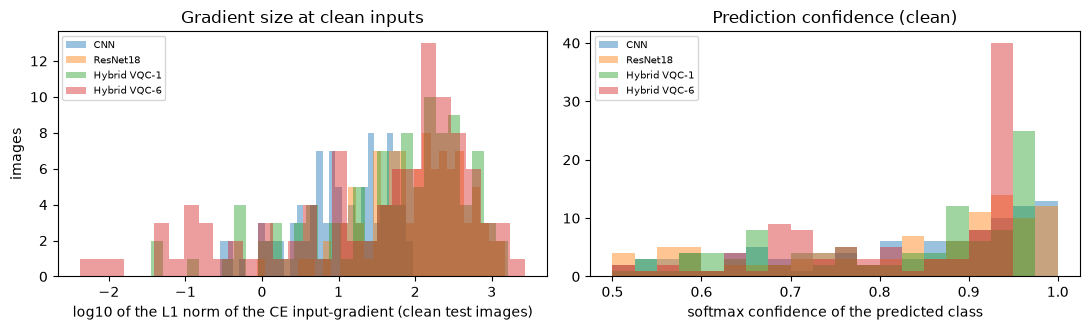

In [21]:
# Gradient-masking diagnostics
print("1) Clean-input gradient of the cross-entropy loss (L1 norm per image) and confidence:")
for nm in MODELS:
    gs = GRAD_STATS[nm]
    print(f"  {nm:13s} median |grad|_1 = {np.median(gs['grad_l1']):.3e} | share with |grad|_1 < 1e-8: {(gs['grad_l1'] < 1e-8).mean():.2f} | share with softmax confidence > 0.999: {(gs['conf'] > 0.999).mean():.2f}")
print("\n2) Is the accuracy under FGSM monotone in eps (a masked / oscillating loss often is not)?")
for nm in MODELS:
    a = [float(acc_pct(nm, "FGSM", e)) for e in EPSILONS]
    print(f"  {nm:13s} FGSM accuracy {[round(v, 1) for v in a]} -> {'rises with eps' if a[-1] > a[0] + 2 else 'does not rise'}")
print("\n3) Does a stronger / gradient-free attack beat the paper's PGD? (positive = standard PGD overestimates the robustness by that many points)")
for nm in MODELS:
    d = {e: acc_pct(nm, "PGD", e) - min(acc_pct(nm, "PGD-margin", e), acc_pct(nm, "Square", e), acc_pct(nm, "FGSM", e)) for e in EPSILONS}
    print(f"  {nm:13s} " + ", ".join(f"eps {e}: {v:+.1f}" for e, v in d.items()))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for nm in MODELS: ax[0].hist(np.log10(GRAD_STATS[nm]["grad_l1"] + 1e-30), bins=30, alpha=.45, label=nm)
ax[0].set_xlabel("log10 of the L1 norm of the CE input-gradient (clean test images)"); ax[0].set_ylabel("images"); ax[0].legend(fontsize=7); ax[0].set_title("Gradient size at clean inputs")
for nm in MODELS: ax[1].hist(GRAD_STATS[nm]["conf"], bins=20, range=(0.5, 1), alpha=.45, label=nm)
ax[1].set_xlabel("softmax confidence of the predicted class"); ax[1].set_title("Prediction confidence (clean)"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()


Worst-case accuracy (%), every L-infinity attack combined:
              eps 0.05  eps 0.15  eps 0.25
CNN               16.0       2.0       0.0
ResNet18           0.0       0.0       0.0
Hybrid VQC-1       0.0       0.0       0.0
Hybrid VQC-6       0.0       0.0       0.0
95 % Wilson intervals:
             eps 0.05 eps 0.15 eps 0.25
CNN             10-24      1-7      0-4
ResNet18          0-4      0-4      0-4
Hybrid VQC-1      0-4      0-4      0-4
Hybrid VQC-6      0-4      0-4      0-4

strongest single attack per model and eps:
  CNN           {0.05: (16.0, 'PGD'), 0.15: (2.0, 'PGD'), 0.25: (0.0, 'PGD')}
  ResNet18      {0.05: (1.0, 'transfer<-Hybrid VQC-1'), 0.15: (0.0, 'transfer<-Hybrid VQC-1'), 0.25: (0.0, 'transfer<-Hybrid VQC-1')}
  Hybrid VQC-1  {0.05: (0.0, 'PGD'), 0.15: (0.0, 'PGD'), 0.25: (0.0, 'PGD')}
  Hybrid VQC-6  {0.05: (0.0, 'transfer<-Hybrid VQC-1'), 0.15: (0.0, 'transfer<-Hybrid VQC-1'), 0.25: (0.0, 'PGD-margin')}


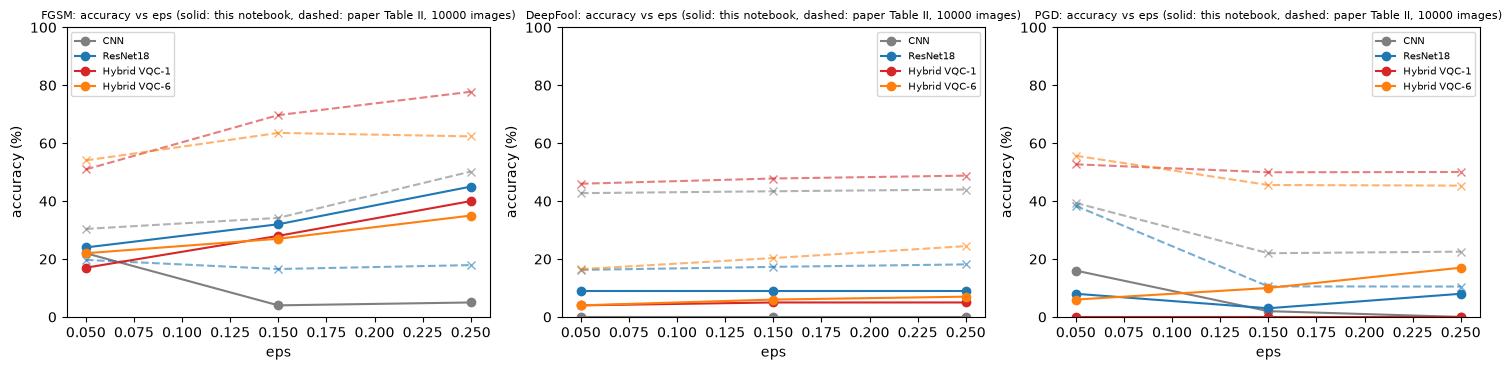

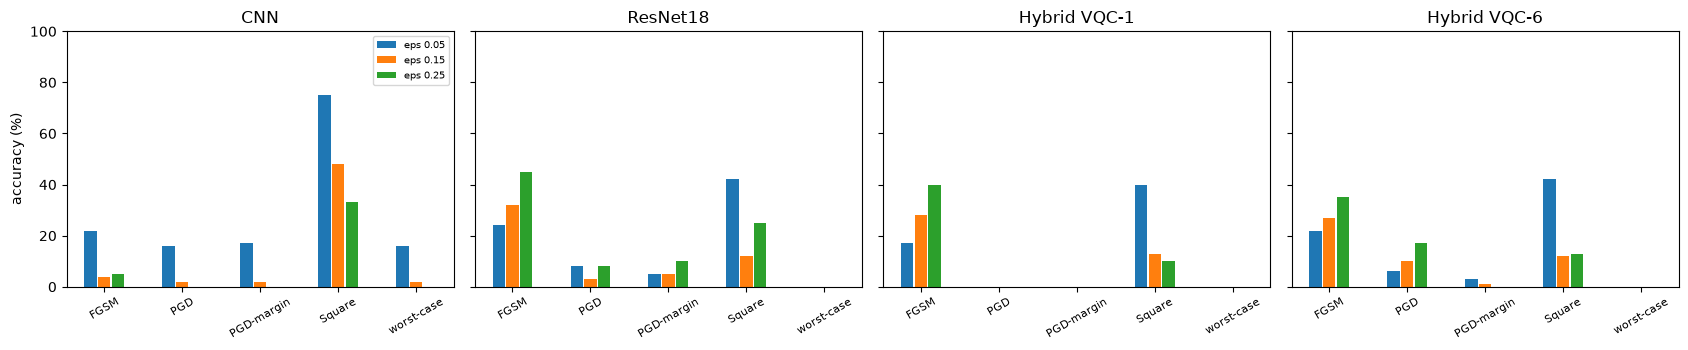

In [22]:
# Per-image worst case over every L-infinity-bounded attack (FGSM, PGD, PGD-margin, Square, all transfers); DeepFool is excluded (norm-unbounded)
WORST = {}
for nm in MODELS:
    keys = ["FGSM", "PGD", "PGD-margin", "Square"] + [k for k in R[nm] if k.startswith("transfer<-")]
    WORST[nm] = {e: np.logical_and.reduce([R[nm][k][e] for k in keys]) for e in EPSILONS}
    for e in EPSILONS: R[nm].setdefault("worst-case", {})[e] = WORST[nm][e]
wc = pd.DataFrame({nm: {f"eps {e}": 100 * WORST[nm][e].mean() for e in EPSILONS} for nm in MODELS}).T.round(1)
lo_hi = pd.DataFrame({nm: {f"eps {e}": "%.0f-%.0f" % wilson(int(WORST[nm][e].sum()), len(XA)) for e in EPSILONS} for nm in MODELS}).T
print("Worst-case accuracy (%), every L-infinity attack combined:"); print(wc.to_string()); print("95 % Wilson intervals:"); print(lo_hi.to_string())
sw = {nm: {e: min(((acc_pct(nm, k, e)), k) for k in ["FGSM", "PGD", "PGD-margin", "Square"] + [k for k in R[nm] if k.startswith("transfer<-")]) for e in EPSILONS} for nm in MODELS}
print("\nstrongest single attack per model and eps:"); [print(f"  {nm:13s}", {e: (round(float(v[0]), 1), v[1]) for e, v in d.items()}) for nm, d in sw.items()]

# Figures: Table II panels (ours solid, paper dashed) and the adaptive attacks
cols = {"CNN": "tab:gray", "ResNet18": "tab:blue", "Hybrid VQC-1": "tab:red", "Hybrid VQC-6": "tab:orange"}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a_, atk in zip(ax, ("FGSM", "DeepFool", "PGD")):
    for nm in MODELS:
        a_.plot(EPSILONS, [acc_pct(nm, atk, e) for e in EPSILONS], "o-", c=cols[nm], label=nm)
        pr = PAPER_TABLE.get(PAPER_N, {}).get(nm)
        if pr: a_.plot(EPSILONS, pr[atk], "x--", c=cols[nm], alpha=.6)
    a_.set_title(f"{atk}: accuracy vs eps (solid: this notebook, dashed: paper Table II, {PAPER_N} images)", fontsize=8); a_.set_xlabel("eps"); a_.set_ylabel("accuracy (%)"); a_.set_ylim(0, 100); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for a_, nm in zip(ax, MODELS):
    atks = ["FGSM", "PGD", "PGD-margin", "Square", "worst-case"]; w_ = 0.16
    for j, e in enumerate(EPSILONS):
        a_.bar(np.arange(len(atks)) + (j - 1) * w_ * 1.1, [acc_pct(nm, k, e) for k in atks], w_, label=f"eps {e}")
    a_.set_xticks(range(len(atks))); a_.set_xticklabels(atks, rotation=30, fontsize=8); a_.set_title(nm); a_.set_ylim(0, 100)
ax[0].set_ylabel("accuracy (%)"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()


## 7. Paper vs this notebook: a verdict per claim

Rules: a number is **reproduced** if it is within 2 accuracy points (tolerance 0.05 for expressibility), otherwise **not reached** (ours lower) or **exceeded** (ours higher) with the gap; **cannot be checked** when the paper gives no matching number for this configuration. Qualitative claims are evaluated from our own numbers with the stated rule. Remember that the attacked subset is small, so each accuracy has a margin of roughly +-8 points.


In [23]:
PN = 10000 if N_IMAGES >= 5000 else 1000
PT = PAPER_TABLE[PN]
def verdict(ours, paper, tol=2.0):
    if paper is None: return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded by {d:.1f}" if d > 0 else f"not reached (gap {-d:.1f})")
rows = []
# (a) clean accuracy
for nm in MODELS:
    pp = PT.get(nm); rows.append(dict(claim=f"clean accuracy, {nm}", paper=pp["clean"] if pp else None, notebook=round(100 * CLEAN[nm], 2), verdict=verdict(100 * CLEAN[nm], pp["clean"] if pp else None)))
# (b) expressibility
for kind in ("vqc1", "vqc6"):
    e = float(expr_df[(expr_df.circuit == kind.upper().replace("VQC", "VQC-")) & (expr_df.layers == Q_LAYERS[kind])].expressibility.iloc[0])
    rows.append(dict(claim=f"expressibility {kind.upper().replace('VQC', 'VQC-')} ({Q_LAYERS[kind]} layer(s))", paper=EXPR_PAPER[kind], notebook=e, verdict=verdict(e, EXPR_PAPER[kind], 0.05)))
# (c) single table cells: how many of the 9 attack cells of each row are within 2 / 5 points
for nm in MODELS:
    pp = PT.get(nm)
    if not pp: rows.append(dict(claim=f"Table II attack cells, {nm}", paper=None, notebook=None, verdict="cannot be checked")); continue
    diffs = [abs(acc_pct(nm, atk, e) - pp[atk][i]) for atk in ("FGSM", "DeepFool", "PGD") for i, e in enumerate(EPSILONS)]
    rows.append(dict(claim=f"Table II attack cells (9), {nm}", paper="9 cells", notebook=f"{sum(d <= 2 for d in diffs)} within 2 pts, {sum(d <= 5 for d in diffs)} within 5 pts, median gap {np.median(diffs):.1f}",
                     verdict="reproduced" if sum(d <= 2 for d in diffs) >= 8 else "not reached (cells differ)"))
# (d) hybrid beats classical ResNet-18 under the paper's attacks
for hy in ("Hybrid VQC-1", "Hybrid VQC-6"):
    for atk in ("FGSM", "DeepFool", "PGD"):
        k = sum(acc_pct(hy, atk, e) > acc_pct("ResNet18", atk, e) for e in EPSILONS)
        rows.append(dict(claim=f"{hy} more accurate than ResNet18 under {atk}", paper="3 of 3 eps (Table II)", notebook=f"{k} of 3 eps", verdict="reproduced" if k == 3 else ("partly reproduced" if k > 0 else "not reached")))
# (e) FGSM accuracy rises with eps for the hybrid VQC-1
a = [acc_pct("Hybrid VQC-1", "FGSM", e) for e in EPSILONS]
rows.append(dict(claim="Hybrid VQC-1 FGSM accuracy rises with eps", paper="50.9 -> 69.7 -> 77.8", notebook=" -> ".join(f"{v:.1f}" for v in a), verdict="reproduced" if a[-1] > a[0] + 2 else "not reached"))
# (f) transfer-learning classical model less robust than the scratch CNN
k = sum(acc_pct("CNN", atk, e) > acc_pct("ResNet18", atk, e) for atk in ("FGSM", "PGD") for e in EPSILONS)
rows.append(dict(claim="CNN without transfer learning more accurate than ResNet18 under FGSM and PGD", paper="yes (Table II, text IV-A)", notebook=f"{k} of 6 cells", verdict="reproduced" if k == 6 else ("partly reproduced" if k > 0 else "not reached")))
# (g) adaptive extension: does 'hybrid is more resilient' survive the worst case over all L-infinity attacks?
for hy in ("Hybrid VQC-1", "Hybrid VQC-6"):
    gaps = [100 * (WORST[hy][e].mean() - WORST["ResNet18"][e].mean()) for e in EPSILONS]
    rows.append(dict(claim=f"[added] {hy} worst-case accuracy above ResNet18 by > 5 points (adaptive attacks)", paper="implied by the conclusion", notebook="gaps " + ", ".join(f"{g:+.1f}" for g in gaps),
                     verdict="holds" if min(gaps) > 5 else "not supported"))
VERD = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 90); print(VERD.to_string(index=False))
print("\nside by side, accuracy under attack (ours / paper), %s images:" % PN)
sb = []
for nm in MODELS:
    pp = PT.get(nm)
    for atk in ("FGSM", "DeepFool", "PGD"):
        sb.append({"model": nm, "attack": atk, **{f"eps {e}": f"{acc_pct(nm, atk, e):.1f} / {pp[atk][i]:.1f}" if pp else f"{acc_pct(nm, atk, e):.1f} / -" for i, e in enumerate(EPSILONS)}})
print(pd.DataFrame(sb).to_string(index=False))


                                                                                   claim                     paper                                        notebook                    verdict
                                                                     clean accuracy, CNN                     80.95                                           80.65                 reproduced
                                                                clean accuracy, ResNet18                      89.5                                            79.2     not reached (gap 10.3)
                                                            clean accuracy, Hybrid VQC-1                     82.35                                           79.85      not reached (gap 2.5)
                                                            clean accuracy, Hybrid VQC-6                      84.3                                            79.1      not reached (gap 5.2)
                                                  

## 8. Reading the paper critically

All numbers below are from the executed run above (seed 42, `N_IMAGES = 10000`, 100 attacked test images per model, so every attack accuracy carries a 95 % margin of about +-10 points).

1. **The central claim is not reproduced.** In the paper's Table II the hybrid ResNet-18 models keep 45 to 78 % under FGSM, 16 to 49 % under DeepFool and 45 to 56 % under PGD, against 17 to 20 %, 16 to 18 % and 10 to 38 % for the classical ResNet-18. Here the hybrid models are *not* more accurate than the classical ResNet-18 under FGSM or DeepFool at any epsilon (FGSM at eps 0.15: classical 32 %, VQC-1 28 %, VQC-6 27 %), and under PGD only VQC-6 is above the classical head, at two of three epsilons (6 / 10 / 17 % against 8 / 3 / 8 %), a difference of a few images out of 100. Not one of the 36 attack cells of the four rows is within 2 points of the paper, and only two are within 5.
2. **Under attacks designed against the model, nothing is left.** The per-image worst case over FGSM, PGD, margin-loss PGD, Square and all transfer attacks is 0 % at every epsilon for the classical ResNet-18 and for both hybrids (95 % interval 0 to 4 %). The only model with a non-zero floor is the small CNN trained from scratch at eps = 0.05 (16 %), the opposite of the paper's statement that hybrid models are the more resilient ones; the added claim "hybrid worst case above classical by 5 points" is therefore *not supported*.
3. **The one place where the quantum layer changes the picture is gradient masking, and it flatters the hybrid.** Under the paper's cross-entropy PGD the VQC-6 model keeps 6 / 10 / 17 % while the margin-loss PGD leaves 3 / 1 / 0 % and the PGD examples crafted on VQC-1 leave 0 % at every epsilon: the standard attack overestimates the robustness of VQC-6 by up to 17 points (diagnostic 3 above), the same pattern as in other papers of this repository. For the classical head the effect is absent (+3, -2, -2 points). The cross-entropy loss of the circuit is simply a worse attack objective, not a harder model.
4. **"Accuracy rises with eps under FGSM" is not a quantum signature.** The paper highlights that VQC-1's FGSM accuracy rises from 51 to 78 % as eps grows. We see the same rise for the classical ResNet-18 (24 -> 32 -> 45 %), VQC-1 (17 -> 28 -> 40 %) and VQC-6 (22 -> 27 -> 35 %): a single large signed step overshoots the linear region where the gradient is informative, so a *stronger* perturbation can be a *weaker* attack. The iterated attacks, which do not have this problem, send all three to about 0 %.
5. **Large eps is not a robustness test.** With pixels in [0, 1], eps = 0.25 allows +-64 grey levels per pixel; random-sign noise of that size already drops every model to 50 to 60 % (chance for a balanced task). An accuracy of about 50 % (the paper's hybrid PGD column) is the signature of a model that predicts one class for everything, not of resistance. The paper does not say whether epsilon refers to [0, 1] pixels or to ImageNet-normalised tensors (where 0.25 is about 0.056 in pixel units); we could not test this and it may explain part of the gap.
6. **Dead units create fake robustness in the classical baseline too.** For 9 % of the test images the classical head (only 4 ReLU units) has an exactly zero input gradient (most likely all four ReLU units are inactive for these images), so DeepFool cannot move them and the DeepFool accuracy of the classical ResNet-18 is stuck at 9 %. A baseline that small makes every comparison fragile; the paper's classical head is just as small.
7. **Statistics.** The paper gives single runs without intervals or seeds, and trains on different image subsets for different models (1,000, 5,000, 10,000), so the rows are not paired. Here all models see the same images and the same 100 attacked patches, but the sample is still small (+-10 points) and one seed is used.
8. **Circuits.** The paper's VQC-1 and VQC-6 exist only as figures. With circuits 1 and 6 of Sim et al. we match VQC-6's expressibility (0.003 against 0.011) but not VQC-1's (0.30 against 1.431), so our VQC-1 is probably not the paper's circuit. VQC-1 as built has no entangling gate: it computes four independent single-qubit functions, i.e. a classical-simulable layer; its failure under PGD (0 %) is the same as the classical model's.
9. **What this notebook cannot say.** One seed; 100 attacked images; centre crop of 48 pixels and a frozen ResNet-18 give clean accuracies of 79 to 81 % instead of the paper's 82 to 89 %; PGD uses 10 steps, margin PGD 10 steps without restarts, Square only 40 queries per image (a weak black-box attack, so its high accuracies are not evidence of robustness); DeepFool's "epsilon" is interpreted as overshoot. A stronger attack budget can only lower the numbers above, so the conclusion that the hybrid models are not more robust than the classical ones in this setup is conservative.

**Verdict.** *partially reproduced*: the pipeline, circuits (VQC-6 expressibility) and the qualitative facts that all models are fragile and that FGSM accuracy is non-monotone in eps reproduce; the headline claim that the hybrid classical-quantum models are more resilient does not, and the part of it that appears under the cross-entropy PGD (VQC-6) vanishes under adaptive attacks.


## 9. Exercises

1. **Gradient masking test.** Re-run section 5 with `PGD_STEPS = 50` and `ADAPT_STEPS = 50`. Does the gap between the standard PGD and the margin-loss PGD of the hybrid model grow? What does that say about the quantum layer's loss surface?
2. **Circuit depth.** Set `Q_LAYERS = {"vqc1": 3, "vqc6": 3}` (more expressible, section 4) and retrain. Do clean accuracy and worst-case robustness move together or against each other?
3. **Fair classical twin.** The paper's classical head has only 4 hidden neurons. Replace it with `Linear(512, 64) -> ReLU -> Linear(64, 2)`; is the "hybrid is more robust" gap still there?
4. **Adversarial training.** Train the classical head on FGSM-perturbed features' images (eps = 0.05) for a few epochs and measure its worst-case accuracy; compare with the best hybrid model without adversarial training.
5. **Noise.** Replace `default.qubit` by `default.mixed` with a depolarizing channel after every gate (p = 0.01) or by shot sampling (`shots=1000`) for the attack gradients only. Does the attack still work, and does the hybrid model become "more robust" simply because its gradients become noisy?
